# Combined clonal dynamics (EDFig2a-c)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.append("../../analysis/")
sys.path.append("../../sim/")
import clones

import pickle

def save_object(obj, filename):
    with open(filename, 'wb') as outp:  # Overwrites any existing file.
        pickle.dump(obj, outp, pickle.HIGHEST_PROTOCOL)

def load_object(filename):
    with open(filename, 'rb') as outp:  # Overwrites any existing file.
        return pickle.load(outp)


from matplotlib import rcParams
# Set global font size for all axes
rcParams['axes.labelsize'] = 12
rcParams['xtick.labelsize'] = 10
rcParams['ytick.labelsize'] = 10
rcParams['legend.fontsize'] = 7.5
rcParams['font.size'] = 10  # General font size
rcParams['text.usetex'] = False
rcParams['font.family'] = 'sans-serif'
rcParams['font.sans-serif'] = ['Arial']
rcParams['svg.fonttype'] = 'none'
rcParams['lines.markersize']  = 3
rcParams['lines.linewidth']  = 1.5

rcParams['axes.labelsize'] = 10
rcParams['xtick.labelsize'] = 7.5
rcParams['ytick.labelsize'] =  7.5
rcParams['legend.fontsize'] = 7.5
rcParams['font.size'] = 10  # General font size
rcParams['axes.titlesize'] = 10
rcParams['text.usetex'] = False
rcParams['font.family'] = 'sans-serif'
rcParams['font.sans-serif'] = ['Arial']
rcParams['svg.fonttype'] = 'none'
rcParams['lines.markersize']  = 3
rcParams['lines.linewidth']  = 1.5


def get_bootstrap_ci(bootstrap_samples, axis=0, confidence=0.95):
    """
    Calculate confidence intervals from bootstrap samples along a specified axis.
    
    Parameters:
    -----------
    bootstrap_samples : array-like
        3D array of bootstrap samples where:
        - First dimension is the number of bootstrap samples
        - Second and third dimensions are your original 2D data shape
    axis : int, default=0
        The axis of the original 2D data along which to calculate CIs
        0 = calculate CI for each column
        1 = calculate CI for each row
    confidence : float, default=0.95
        Confidence level (0 to 1)
        
    Returns:
    --------
    tuple
        (lower_bounds, upper_bounds, means)
        Each is an array corresponding to the CIs and means along the specified axis
    """
    # Convert input to numpy array if it isn't already
    samples = np.asarray(bootstrap_samples)
    
    # Calculate alpha for confidence interval
    alpha = (1 - confidence) / 2
    
    # Calculate percentiles and mean along the bootstrap samples dimension
    # Add 1 to axis because original axis 0/1 is now 1/2 due to bootstrap dimension
    lower_bounds = np.nanpercentile(samples, alpha * 100, axis=0)
    upper_bounds = np.nanpercentile(samples, (1 - alpha) * 100, axis=0)
    means = np.mean(samples, axis=0)
    
    # If axis=0 (columns), we want stats for each column of original data
    # If axis=1 (rows), we want stats for each row of original data
    if axis == 0:
        return lower_bounds, upper_bounds, means
    elif axis == 1:
        return (lower_bounds.T, upper_bounds.T, means.T)
    else:
        raise ValueError("Axis must be 0 or 1")

    
#Load clonal data

exp_folder = '../../experiment/homeo/'
exp_data = load_object(exp_folder + 'data_ctr.pkl')
livesize = exp_data['livesize']

exp_data_F = load_object(exp_folder + 'data_ctr_F.pkl')
livesize_F = exp_data_F['livesize']

exp_data_M = load_object(exp_folder + 'data_ctr_M.pkl')
livesize_M = exp_data_M['livesize']

colm = {'M30': 'r', 'M1': 'b', 'M14': 'g', 'M3': 'tab:orange', 'M1bis': 'tab:purple',
        'F3':  'r', 'F4': 'b', 'F11': 'g', 'F9': 'tab:orange', 'F10': 'tab:purple'}
fmice = ['F3', 'F4', 'F11', 'F9', 'F10']
mmice = ['M30', 'M1', 'M14', 'M3', 'M1bis']
sex = ['F', 'M']

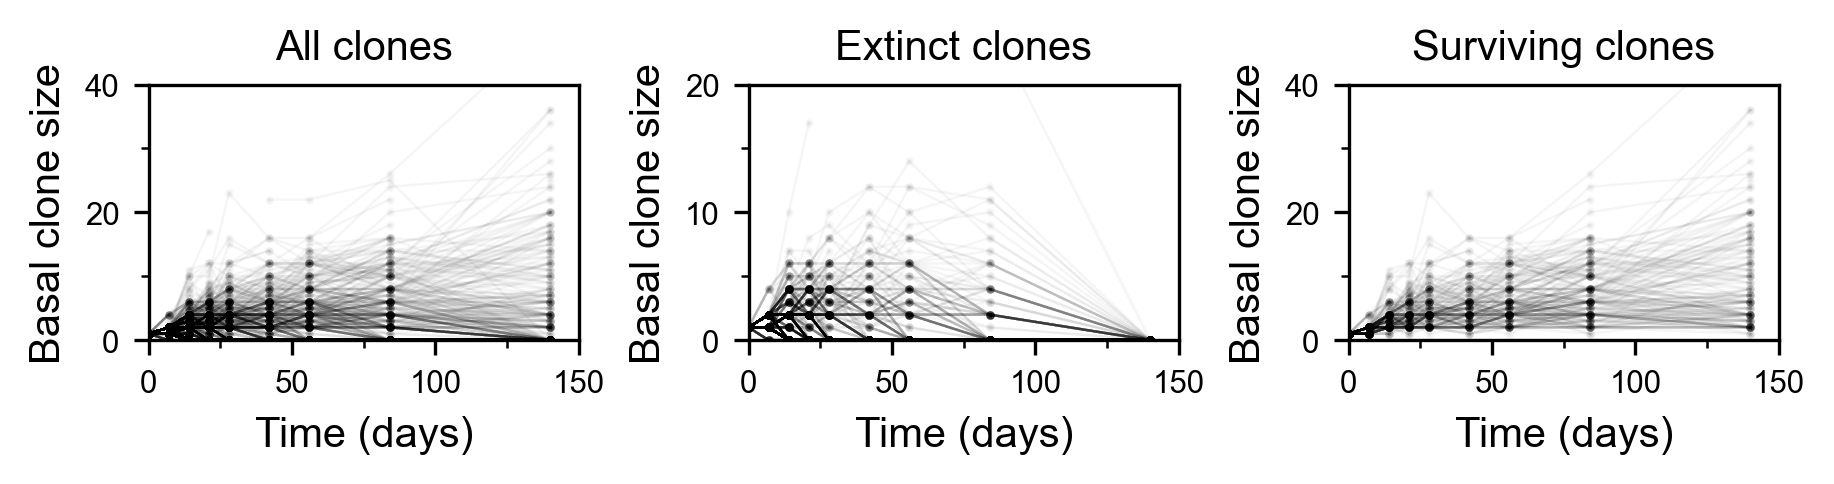

In [2]:

exp_folder = '../../experiment/homeo/'
exp_data = load_object(exp_folder + 'data_ctr.pkl')
livesize = exp_data['livesize']

ls = livesize[:,:,0].astype('float')
ls[ls < 0] = np.nan

ls = np.hstack([np.ones((ls.shape[0],1)), ls])
times = [0] + list(exp_data['ctrTimeClonesize'])

fig, axs = plt.subplots(1, 3, figsize=(6, 1.5), dpi=300, constrained_layout=True)

# Plot for all clones
axs[0].plot(times, ls[:,:].T, 'k-o', alpha = 0.04, linewidth = 0.6, markersize = 1.)
axs[0].set_xlabel('Time (days)')
axs[0].set_ylabel('Basal clone size')
axs[0].set_ylim([0,40])
axs[0].set_yticks(np.arange(0,41,20))
axs[0].set_yticks(np.arange(0,41,10), minor = True)
axs[0].set_xlim([0, 150])
axs[0].set_xticks(np.arange(0,151,50))
axs[0].set_xticks(np.arange(0,151,25), minor = True)
axs[0].set_title('All clones')
plt.savefig('Figures/F1d_temporal.pdf')
#plt.show()

# Plot for extinct clones
clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'], use_t0 = False)
ls_extinct = clone_anal.livesize[clone_anal.extinct(),:,0].astype('float')
ls_extinct = np.hstack([np.ones((ls_extinct.shape[0],1)), ls_extinct])
ls_extinct[ls_extinct < 0] = np.nan
axs[1].plot(times, ls_extinct[:,:].T, 'k-o', alpha = 0.04, linewidth = 0.6, markersize = 1.)
axs[1].set_xlabel('Time (days)')
axs[1].set_ylabel('Basal clone size')
axs[1].set_ylim([0,20])
axs[1].set_yticks(np.arange(0,21,10))
axs[1].set_yticks(np.arange(0,21,5), minor = True)
axs[1].set_xlim([0, 150])
axs[1].set_xticks(np.arange(0,151,50))
axs[1].set_xticks(np.arange(0,151,25), minor = True)
axs[1].set_title('Extinct clones')

# Plot for surviving clones
ls_surviving = clone_anal.livesize[~clone_anal.extinct(),:,0].astype('float')
ls_surviving = np.hstack([np.ones((ls_surviving.shape[0],1)), ls_surviving])
ls_surviving[ls_surviving < 0] = np.nan
axs[2].plot(times, ls_surviving[:,:].T, 'k-o', alpha = 0.04, linewidth = 0.6, markersize = 1.)
axs[2].set_xlabel('Time (days)')
axs[2].set_ylabel('Basal clone size')
axs[2].set_ylim([0,40])
axs[2].set_yticks(np.arange(0,41,20))
axs[2].set_yticks(np.arange(0,41,10), minor = True)
axs[2].set_xlim([0, 150])
axs[2].set_xticks(np.arange(0,151,50))
axs[2].set_xticks(np.arange(0,151,25), minor = True)
axs[2].set_title('Surviving clones')
plt.show()


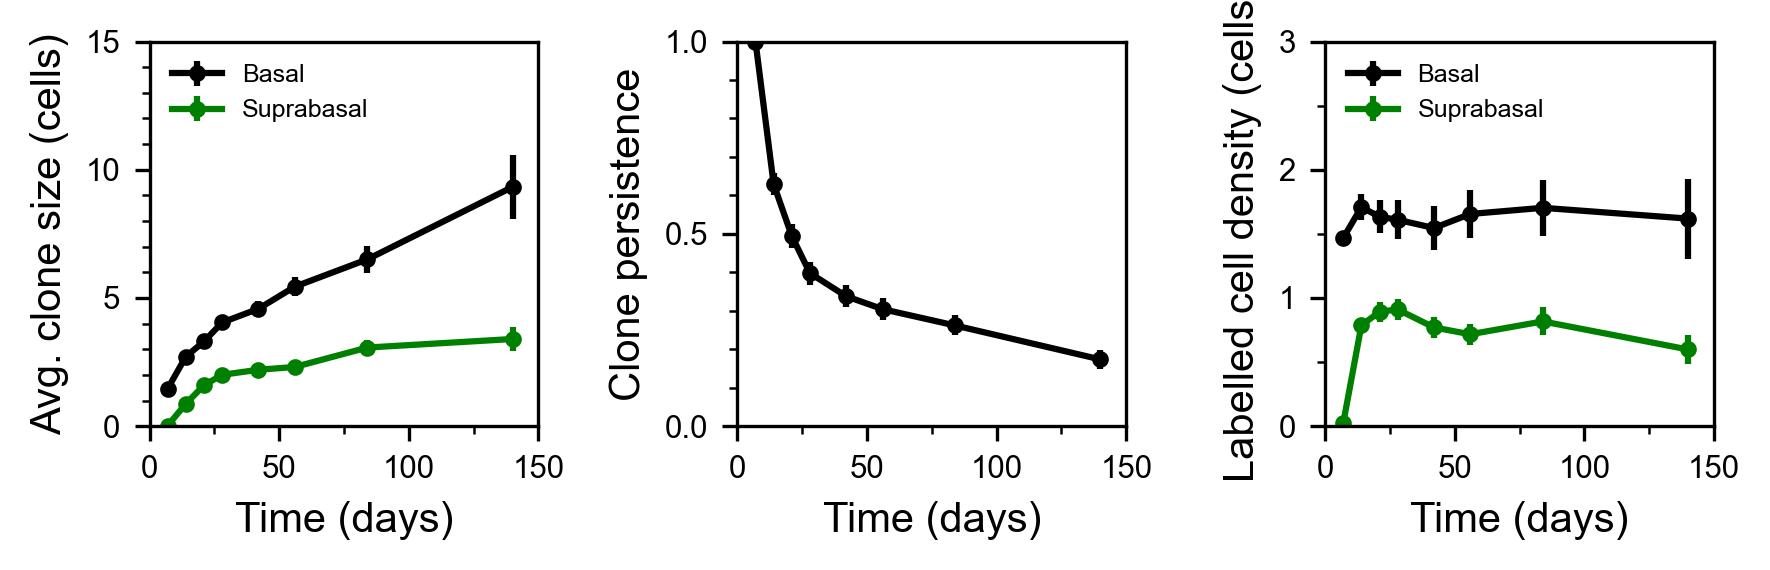

In [3]:
nboots = 10000
exp_folder = '../../experiment/homeo/'
exp_data = load_object(exp_folder + 'data_ctr.pkl')
livesize = exp_data['livesize']
conf = 0.68
fig, axes = plt.subplots(1, 3, figsize=(6, 2), dpi=300)

# Subplot 1: Average Clone Size
clone_anal = clones.xanalysis(livesize, verbose=False, tvals=exp_data['ctrTimeClonesize'])
db = clone_anal.boot('av_bas_cs', nboots, None, sample_size=None)
lower68, upper68, means95 = get_bootstrap_ci(db, 0, confidence=conf)
axes[0].errorbar(clone_anal.tvals, clone_anal.av_bas_cs, upper68-lower68, fmt='ko-', label='Basal')
db = clone_anal.boot('av_sup_cs', nboots, None, sample_size=None)
lower68, upper68, means95 = get_bootstrap_ci(db, 0, confidence=conf)
axes[0].errorbar(clone_anal.tvals, clone_anal.av_sup_cs, upper68-lower68, fmt='go-', label='Suprabasal')
axes[0].set_xlabel('Time (days)')
axes[0].set_ylabel('Avg. clone size (cells)')
axes[0].legend(frameon=False, fontsize=6, loc='upper left')
axes[0].set_ylim([0, 10])
axes[0].set_yticks(np.arange(0, 16, 5))
axes[0].set_yticks(np.arange(0, 16, 1), minor=True)
axes[0].set_xlim([0, 150])
axes[0].set_xticks(np.arange(0, 151, 50))
axes[0].set_xticks(np.arange(0, 151, 25), minor=True)

# Subplot 2: Persistence
db = clone_anal.boot('pers', nboots, None, sample_size=None)
lower68, upper68, means95 = get_bootstrap_ci(db, 0, confidence=conf)
axes[1].errorbar(clone_anal.tvals, clone_anal.pers, upper68-lower68, fmt='ko-')
axes[1].set_xlabel('Time (days)')
axes[1].set_ylabel('Clone persistence')
axes[1].set_ylim([0, 1])
axes[1].set_yticks(np.arange(0, 1.1, 0.5))
axes[1].set_yticks(np.arange(0, 1.1, 0.1), minor=True)
axes[1].set_xlim([0, 150])
axes[1].set_xticks(np.arange(0, 151, 50))
axes[1].set_xticks(np.arange(0, 151, 25), minor=True)

# Subplot 3: Labelled Cell Density
db = clone_anal.boot('lcd', nboots, None, sample_size=None)
lower68, upper68, means95 = get_bootstrap_ci(db, 0, confidence=conf)
axes[2].errorbar(clone_anal.tvals, clone_anal.lcd, upper68-lower68, fmt='ko-', label = 'Basal')
db = clone_anal.boot('av_full_sup_cs', nboots, None, sample_size=None)
lower68, upper68, means95 = get_bootstrap_ci(db, 0, confidence=conf)
axes[2].errorbar(clone_anal.tvals, clone_anal.av_full_sup_cs, upper68-lower68, fmt='go-', label = 'Suprabasal')
axes[2].legend(frameon=False, fontsize=6, loc='upper left')
axes[2].set_xlabel('Time (days)')
axes[2].set_ylabel('Labelled cell density (cells)')
axes[2].set_ylim([0, 3])
axes[2].set_yticks(np.arange(0, 3.1, 1))
axes[2].set_yticks(np.arange(0, 3.1, 0.5), minor=True)
axes[2].set_xlim([0, 150])
axes[2].set_xticks(np.arange(0, 151, 50))
axes[2].set_xticks(np.arange(0, 151, 25), minor=True)


plt.tight_layout()
plt.savefig('Figures/SF2abc_av.pdf')
plt.show()
